![Ironhack logo](https://user-images.githubusercontent.com/23629340/40541063-a07a0a8a-601a-11e8-91b5-2f13e4e6b441.png)

# 02 | Pipelines and Models

*Project 2 — Machine Learning: From Data to Predictions*

**Team:** Rizki
**Dataset:** Coffee Quality Institute (CQI) green-coffee reviews, Arabica samples (1,310 rows after cleaning). Scraped Jan 2018 by jldbc (github.com/jldbc/coffee-quality-database). The repo is MIT-licensed; the licence of CQI's underlying data is unclear (see references/sources.json).

---

Steps 5 to 8 of the workflow: build the pipeline, compare models fairly, tune the best, and choose the threshold. Everything here uses the training set only.

> **Done when:** you have a comparison table of at least three model families on the same folds against the baseline, the best one or two tuned, and a final model chosen for reasons you can state.

The sections below are a suggested route, not a form to fill in. Add sections, drop them, reorder them — what is graded is the work, not whether you kept the scaffold.

---
## 0. Setup

Loading and splitting live in `src/functions.py` (`load_arabica`, `split_once`), so notebooks 01, 02 and 03 use exactly the same rows. The seed and paths come from `src/config.py`.

In [1]:
import sys
sys.path.append("..")          # so `src` is importable from inside notebooks/

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from src.functions import *

pd.set_option("display.max_columns", 100)
sns.set_theme(style="whitegrid")

---
## 1. Load and split

The same loading and the same split as notebook 01. Put the code in `src/functions.py` so both notebooks use exactly the same rows.

Loading and splitting live in `src/functions.py` (`load_arabica`, `split_once`), so notebooks 01, 02 and 03 use exactly the same rows. The seed and paths come from `src/config.py`.

In [2]:
import os
from src.config import PATHS, RANDOM_STATE

df = load_arabica(PATHS["clean_data"])
X_train, X_test, y_train, y_test = split_once(df, RANDOM_STATE)
# X_test and y_test are NOT used in this notebook: the test set waits for notebook 03

numeric_cols, categorical_cols = get_feature_columns(X_train)
cv = make_cv(RANDOM_STATE)        # the same 5 folds as the baseline in notebook 01

print(df.shape, X_train.shape, X_test.shape)    # expect (1310, 20) (1048, 8) (262, 8)

(1310, 20) (1048, 8) (262, 8)


---
## 2. The preprocessing pipeline

A `ColumnTransformer` with one branch per column type: impute, scale, encode. **Everything that learns from data goes inside**, so cross-validation refits it on every fold.

One branch per column type:
- **numbers** (moisture, altitude, the two defect counts): fill gaps with the median, then put them on one scale
- **categories** (country, variety, processing, colour): a gap becomes its own category "missing", then one-hot encode; categories with fewer than 10 samples share one "infrequent" column

Everything that learns from data (the medians, the scale, the list of categories) lives inside the pipeline, so cross-validation recomputes it on every fold. It is like re-calibrating the grinder for each batch, not using settings that peeked at the cup you are about to taste.

In [3]:
preprocessor = make_preprocessor(numeric_cols, categorical_cols)
X_prepared = preprocessor.fit_transform(X_train)        # fitted on the TRAINING set only
names = preprocessor.get_feature_names_out()

print(X_train.shape, "->", X_prepared.shape)
pd.DataFrame(X_prepared, columns=names).head(3).round(2)

(1048, 8) -> (1048, 46)


,num__Moisture,num__altitude_mean_meters,num__Category.One.Defects,num__Category.Two.Defects,cat__Country.of.Origin_Brazil,cat__Country.of.Origin_China,cat__Country.of.Origin_Colombia,cat__Country.of.Origin_Costa Rica,cat__Country.of.Origin_El Salvador,cat__Country.of.Origin_Ethiopia,cat__Country.of.Origin_Guatemala,cat__Country.of.Origin_Honduras,cat__Country.of.Origin_Indonesia,cat__Country.of.Origin_Kenya,cat__Country.of.Origin_Mexico,cat__Country.of.Origin_Nicaragua,cat__Country.of.Origin_Peru,cat__Country.of.Origin_Taiwan,"cat__Country.of.Origin_Tanzania, United Republic Of",cat__Country.of.Origin_Thailand,cat__Country.of.Origin_Uganda,cat__Country.of.Origin_United States (Hawaii),cat__Country.of.Origin_infrequent_sklearn,cat__Variety_Bourbon,cat__Variety_Catimor,cat__Variety_Catuai,cat__Variety_Caturra,cat__Variety_Hawaiian Kona,cat__Variety_Mundo Novo,cat__Variety_Other,cat__Variety_SL14,cat__Variety_SL28,cat__Variety_Typica,cat__Variety_Yellow Bourbon,cat__Variety_missing,cat__Variety_infrequent_sklearn,cat__Processing.Method_Natural / Dry,cat__Processing.Method_Other,cat__Processing.Method_Pulped natural / honey,cat__Processing.Method_Semi-washed / Semi-pulped,cat__Processing.Method_Washed / Wet,cat__Processing.Method_missing,cat__Color_Blue-Green,cat__Color_Bluish-Green,cat__Color_Green,cat__Color_missing
0,0.77,1.39,-0.21,-0.66,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
1,0.77,-1.37,-0.21,-0.47,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0
2,-0.14,-0.04,-0.21,-0.10,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0


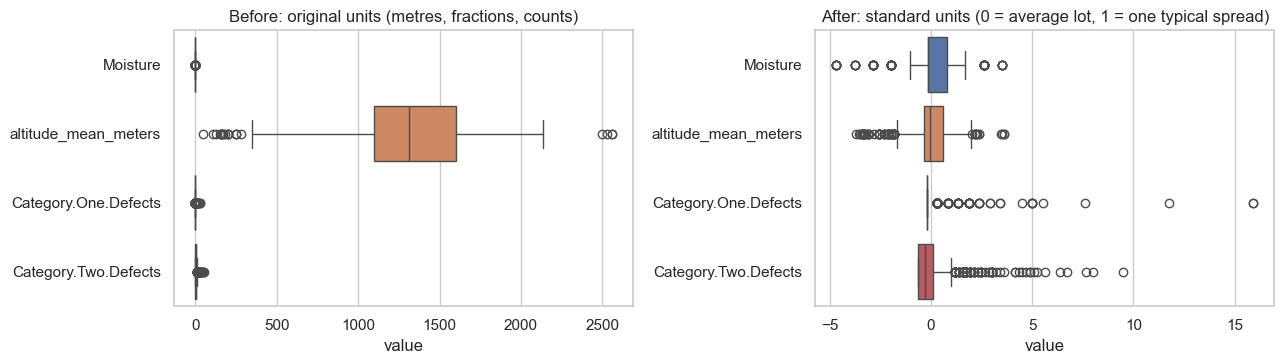

In [4]:
# Feature scaling: the same lots in original units and after the pipeline's StandardScaler (number columns only)
raw = X_train[numeric_cols]
scaled = pd.DataFrame(X_prepared, columns=names)[[f"num__{c}" for c in numeric_cols]]
scaled.columns = numeric_cols

fig, axes = plt.subplots(1, 2, figsize=(13, 3.8))
sns.boxplot(data=raw, orient="h", ax=axes[0])
axes[0].set_title("Before: original units (metres, fractions, counts)")
axes[0].set_xlabel("value")
sns.boxplot(data=scaled, orient="h", ax=axes[1])
axes[1].set_title("After: standard units (0 = average lot, 1 = one typical spread)")
axes[1].set_xlabel("value")
plt.tight_layout()
plt.show()

In [5]:
# Proof that the scaling cell is safe to run after this cell:
same = list(names) == list(preprocessor.get_feature_names_out())
print("names unchanged:", same, "|", len(names), "names")

names unchanged: True | 46 names


---
## 3. First model in the pipeline

One simple model at the end of the pipeline, scored with cross-validation. Is it better than the baseline, and by more than the spread across folds?

In [6]:
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import Ridge

baseline = build_pipeline(DummyRegressor(strategy="mean"), numeric_cols, categorical_cols)
ridge = build_pipeline(Ridge(alpha=1.0), numeric_cols, categorical_cols)

compare_models({"Baseline (mean)": baseline, "Ridge": ridge}, X_train, y_train, cv)

,MAE (validation),MAE spread,R2 (validation),R2 spread,MAE (train)
Ridge,1.658,0.108,0.190,0.039,1.592
Baseline (mean),1.819,0.156,-0.003,0.002,1.817


Ridge lowers the average error from 1.82 to 1.66 cup points (R² 0.19). Training MAE (1.59) and validation MAE (1.66) are close, so it is not memorising. The gain (0.16) is about the size of the fold-to-fold spread, so by my strict rule it is a modest gain. Section 5 checks it fold by fold.

---
## 4. Features

New features added inside the pipeline. Keep a feature only if it improves the cross-validated score, and write down what each one changed.

Two ideas, both built inside the pipeline:
- **missing flags**: a gap in altitude or moisture may itself be a clue about where the sample came from (we saw gaps appear together)
- **total defects**: category 1 plus category 2 defects as one number
Rule: keep a feature only if the validation MAE improves by more than the spread across folds.

In [7]:
from sklearn.ensemble import RandomForestRegressor

variants = {
    "base": {},
    "+ missing flags": {"missing_flags": True},
    "+ total defects": {"total_defects": True},
    "+ both": {"missing_flags": True, "total_defects": True},
}

models4 = {}
for label, options in variants.items():
    models4[f"Ridge | {label}"] = build_pipeline(Ridge(alpha=1.0), numeric_cols, categorical_cols, **options)
    models4[f"Random forest | {label}"] = build_pipeline(
        RandomForestRegressor(n_estimators=200, min_samples_leaf=5, random_state=RANDOM_STATE, n_jobs=-1),
        numeric_cols, categorical_cols, **options)

features_table = compare_models(models4, X_train, y_train, cv)
features_table

,MAE (validation),MAE spread,R2 (validation),R2 spread,MAE (train)
Random forest | + both,1.617,0.122,0.217,0.054,1.279
Random forest | + missing flags,1.621,0.126,0.210,0.051,1.286
Random forest | + total defects,1.625,0.119,0.211,0.056,1.288
Random forest | base,1.629,0.125,0.205,0.054,1.297
Ridge | + missing flags,1.656,0.109,0.190,0.039,1.588
Ridge | + both,1.656,0.109,0.190,0.039,1.588
Ridge | base,1.658,0.108,0.190,0.039,1.592
Ridge | + total defects,1.658,0.108,0.190,0.039,1.592


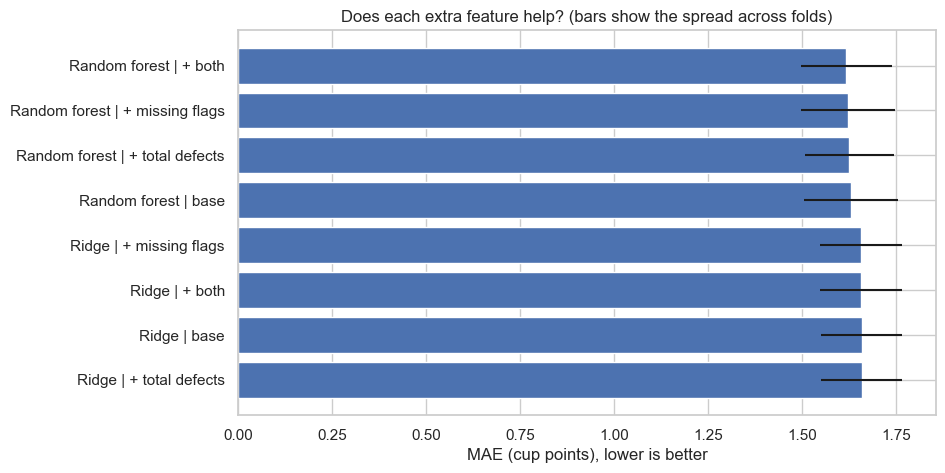

In [8]:
plt.figure(figsize=(9, 5))
plt.barh(features_table.index, features_table["MAE (validation)"], xerr=features_table["MAE spread"])
plt.gca().invert_yaxis()
plt.xlabel("MAE (cup points), lower is better")
plt.title("Does each extra feature help? (bars show the spread across folds)")
plt.show()

No extra feature moves the score by more than 0.012 cup points, against a fold-to-fold spread of about 0.12. Decision: keep neither, best_options = {}.
- missing flags: a gap in altitude or moisture does not tell us anything about the cup score here.
- total defects: for Ridge the score is identical (1.658), because a linear model can add the two defect columns itself. It is like adding a "total defects" line to a cupping sheet that already lists both counts: the cupper adds them in their head.

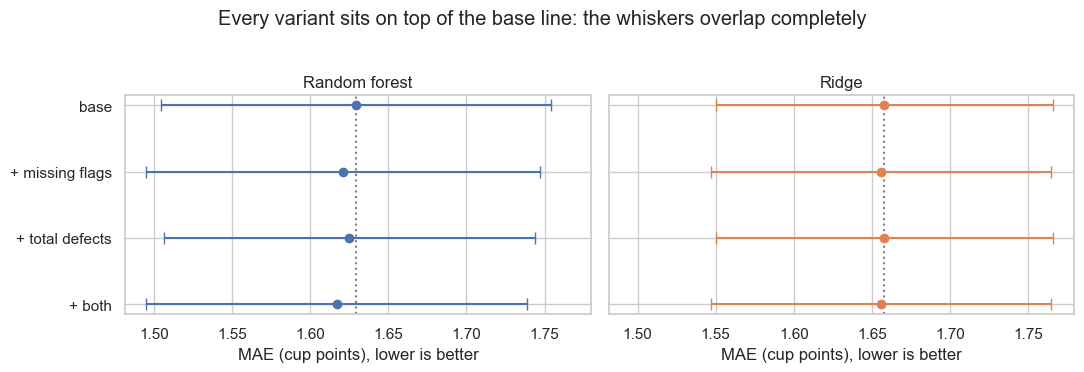

In [9]:
plot_data = features_table.copy()
plot_data["family"] = [name.split(" | ")[0] for name in plot_data.index]
plot_data["variant"] = [name.split(" | ")[1] for name in plot_data.index]

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharex=True, sharey=True)   # same x axis, so the two families compare
for i, (ax, (family, part)) in enumerate(zip(axes, plot_data.groupby("family"))):
    part = part.set_index("variant").loc[list(variants)]            # same order in both panels
    ax.errorbar(part["MAE (validation)"], range(len(part)), xerr=part["MAE spread"],
                fmt="o", capsize=4, color=f"C{i}")
    ax.axvline(part.loc["base", "MAE (validation)"], color="grey", linestyle=":", label="base")
    ax.set_yticks(range(len(part)))
    ax.set_yticklabels(part.index)
    ax.set_title(family)
    ax.set_xlabel("MAE (cup points), lower is better")
axes[0].invert_yaxis()
plt.suptitle("Every variant sits on top of the base line: the whiskers overlap completely", y=1.03)
plt.tight_layout()
plt.show()

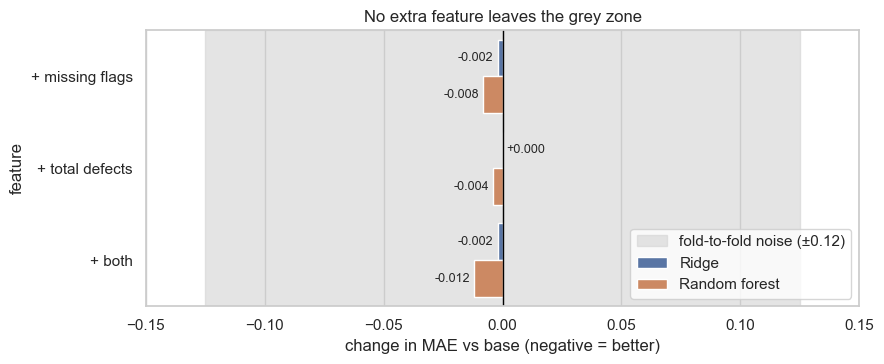

In [10]:
rows = []
for family in ["Ridge", "Random forest"]:
    base_mae = features_table.loc[f"{family} | base", "MAE (validation)"]
    for variant in list(variants)[1:]:                               # every variant except "base"
        rows.append({"family": family, "feature": variant,
                     "change in MAE": features_table.loc[f"{family} | {variant}", "MAE (validation)"] - base_mae})
change = pd.DataFrame(rows)
noise = features_table.loc[["Ridge | base", "Random forest | base"], "MAE spread"].max()

fig, ax = plt.subplots(figsize=(9, 3.8))
ax.axvspan(-noise, noise, color="lightgrey", alpha=0.6, zorder=0, label=f"fold-to-fold noise (±{noise:.2f})")
sns.barplot(data=change, y="feature", x="change in MAE", hue="family", ax=ax)
for container in ax.containers:
    ax.bar_label(container, fmt="%+.3f", padding=3, fontsize=9)
ax.axvline(0, color="black", linewidth=1)
ax.set_xlim(-noise * 1.2, noise * 1.2)
ax.set_xlabel("change in MAE vs base (negative = better)")
ax.set_title("No extra feature leaves the grey zone")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

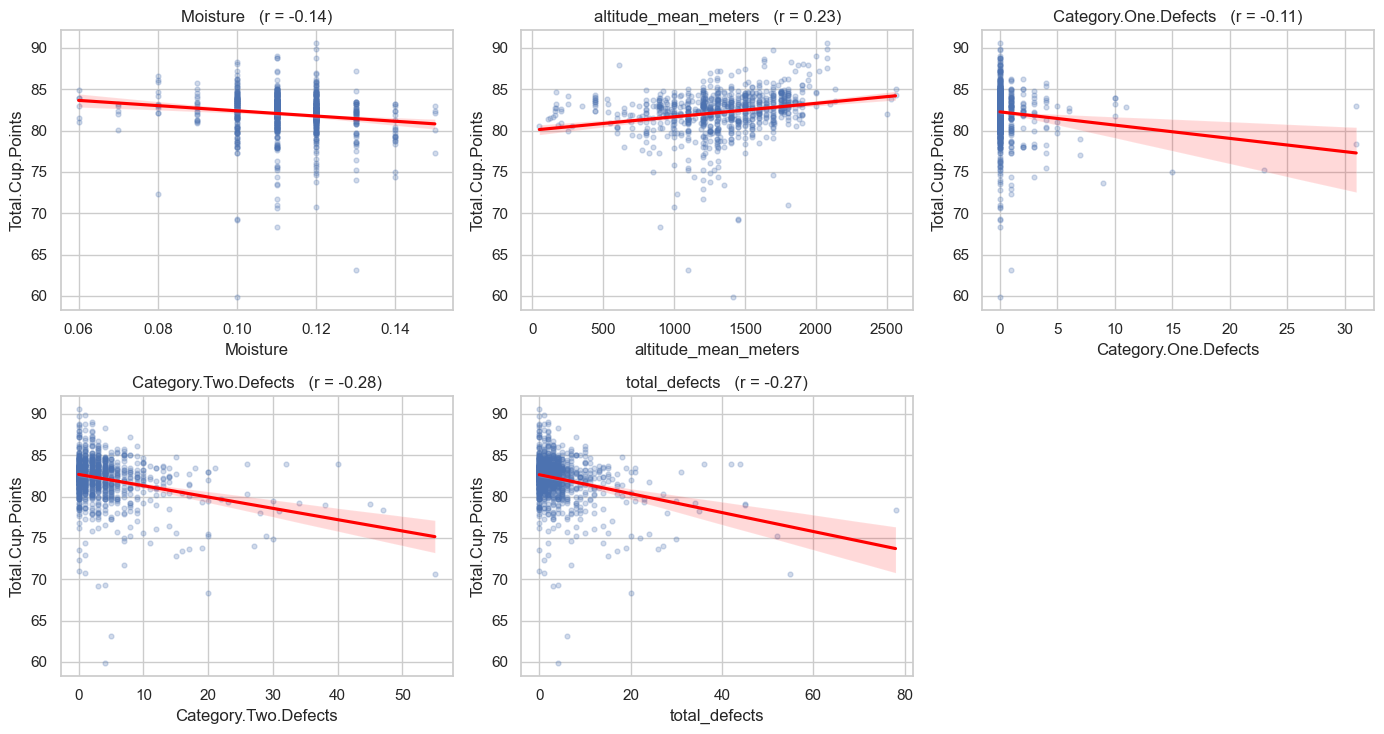

In [11]:
# Scatter plot with a regression line: does each number say anything about the cup score?
train = X_train.copy()
train[TARGET] = y_train
defect_cols = [c for c in numeric_cols if "Defects" in c]
train["total_defects"] = train[defect_cols].sum(axis=1)             # the new feature from this section

features_to_plot = numeric_cols + ["total_defects"]
fig, axes = plt.subplots(2, 3, figsize=(14, 7.5))
for ax, col in zip(axes.ravel(), features_to_plot):
    r = train[[col, TARGET]].corr().iloc[0, 1]                      # r = correlation with the cup score
    sns.regplot(data=train, x=col, y=TARGET, ax=ax, scatter_kws={"alpha": 0.25, "s": 12}, line_kws={"color": "red"})
    ax.set_title(f"{col}   (r = {r:.2f})")
for ax in axes.ravel()[len(features_to_plot):]:
    ax.axis("off")                                                   # hide the unused panel
plt.tight_layout()
plt.show()

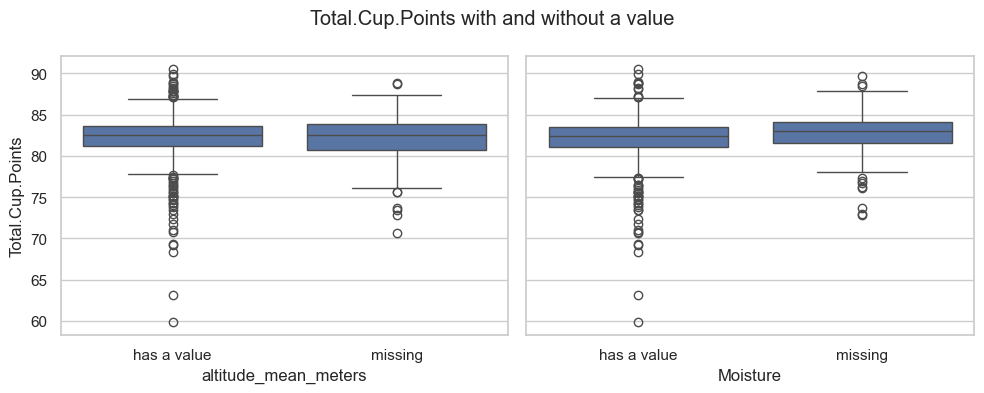

In [12]:
# The missing-flag idea: do lots with a gap score differently? (a box plot, because "missing or not" is a category)
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=True)
for ax, col in zip(axes, ["altitude_mean_meters", "Moisture"]):
    has_value = train[col].isna().map({True: "missing", False: "has a value"})
    sns.boxplot(x=has_value, y=train[TARGET], order=["has a value", "missing"], ax=ax)
    ax.set_xlabel(col)
plt.suptitle("Total.Cup.Points with and without a value")
plt.tight_layout()
plt.show()

---
## 5. Compare models

At least three model families on **the same folds**, with the mean and the spread. A table, and a chart of it.

In [13]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

best_options = {}      # fill in from section 4, for example {"missing_flags": True}; leave {} if nothing helped

models5 = {
    "Baseline (mean)": build_pipeline(DummyRegressor(strategy="mean"), numeric_cols, categorical_cols, **best_options),
    "Ridge (linear)": build_pipeline(Ridge(alpha=10.0), numeric_cols, categorical_cols, **best_options),
    "K-nearest neighbours": build_pipeline(KNeighborsRegressor(n_neighbors=25), numeric_cols, categorical_cols, **best_options),
    "Random forest": build_pipeline(RandomForestRegressor(n_estimators=300, min_samples_leaf=5,
                                    random_state=RANDOM_STATE, n_jobs=-1), numeric_cols, categorical_cols, **best_options),
    "Gradient boosting": build_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                                        numeric_cols, categorical_cols, **best_options),
}

comparison = compare_models(models5, X_train, y_train, cv)
comparison

,MAE (validation),MAE spread,R2 (validation),R2 spread,MAE (train)
Random forest,1.628,0.127,0.206,0.054,1.296
Ridge (linear),1.647,0.118,0.197,0.034,1.596
K-nearest neighbours,1.656,0.133,0.177,0.038,1.591
Gradient boosting,1.724,0.150,0.165,0.086,1.070
Baseline (mean),1.819,0.156,-0.003,0.002,1.817


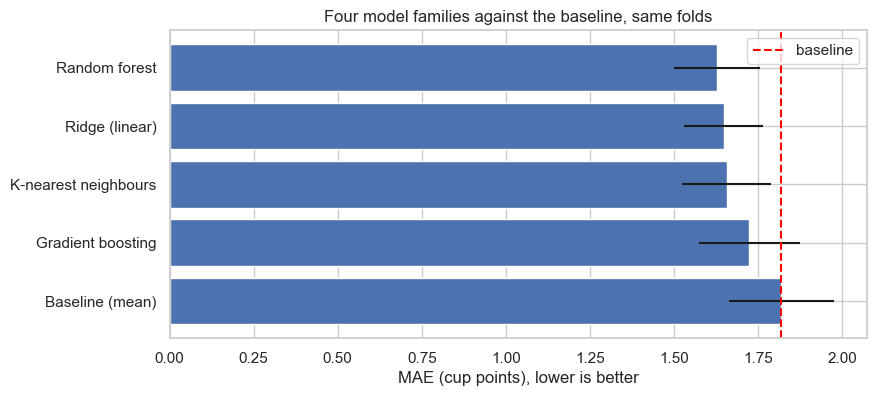

In [14]:
baseline_mae = comparison.loc["Baseline (mean)", "MAE (validation)"]

plt.figure(figsize=(9, 4))
plt.barh(comparison.index, comparison["MAE (validation)"], xerr=comparison["MAE spread"])
plt.axvline(baseline_mae, color="red", linestyle="--", label="baseline")
plt.gca().invert_yaxis()
plt.xlabel("MAE (cup points), lower is better")
plt.legend()
plt.title("Four model families against the baseline, same folds")
plt.show()

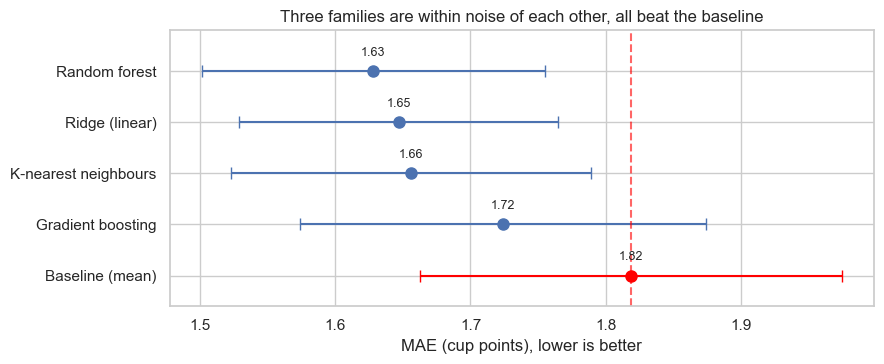

In [15]:
fig, ax = plt.subplots(figsize=(9, 3.8))
y = np.arange(len(comparison))
for i, (name, row) in enumerate(comparison.iterrows()):
    colour = "red" if name.startswith("Baseline") else "C0"
    ax.errorbar(row["MAE (validation)"], i, xerr=row["MAE spread"], fmt="o", capsize=4, color=colour, markersize=8)
    ax.text(row["MAE (validation)"], i - 0.3, f'{row["MAE (validation)"]:.2f}', ha="center", fontsize=9)
ax.axvline(baseline_mae, color="red", linestyle="--", alpha=0.6)
ax.set_yticks(y)
ax.set_yticklabels(comparison.index)
ax.set_ylim(len(comparison) - 0.4, -0.8)                            # best model on top, room for its label
ax.set_xlabel("MAE (cup points), lower is better")
ax.set_title("Three families are within noise of each other, all beat the baseline")
plt.tight_layout()
plt.show()

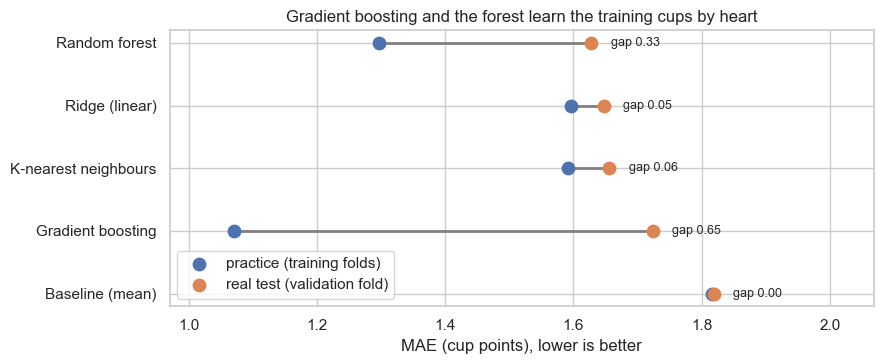

In [16]:
fig, ax = plt.subplots(figsize=(9, 3.8))
for i, (name, row) in enumerate(comparison.iterrows()):
    ax.plot([row["MAE (train)"], row["MAE (validation)"]], [i, i], color="grey", linewidth=2, zorder=1)
    ax.scatter(row["MAE (train)"], i, color="C0", s=80, zorder=2, label="practice (training folds)" if i == 0 else None)
    ax.scatter(row["MAE (validation)"], i, color="C1", s=80, zorder=2, label="real test (validation fold)" if i == 0 else None)
    gap = row["MAE (validation)"] - row["MAE (train)"]
    ax.text(max(row["MAE (train)"], row["MAE (validation)"]) + 0.03, i, f"gap {gap:.2f}", va="center", fontsize=9)
ax.set_yticks(range(len(comparison)))
ax.set_yticklabels(comparison.index)
ax.invert_yaxis()
ax.set_xlim(comparison["MAE (train)"].min() - 0.1, comparison["MAE (validation)"].max() + 0.25)
ax.set_xlabel("MAE (cup points), lower is better")
ax.set_title("Gradient boosting and the forest learn the training cups by heart")
ax.legend(loc="lower left")
plt.tight_layout()
plt.show()

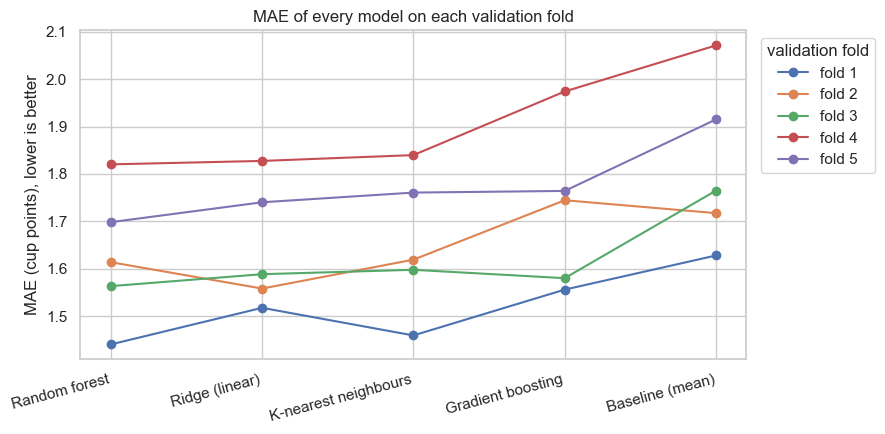

In [17]:
folds = fold_scores(models5, X_train, y_train, cv)                  # helper from src/functions.py
wide = folds.pivot(index="fold", columns="model", values="MAE")[comparison.index]    # best model first
plot_fold_lines(wide, "MAE of every model on each validation fold")

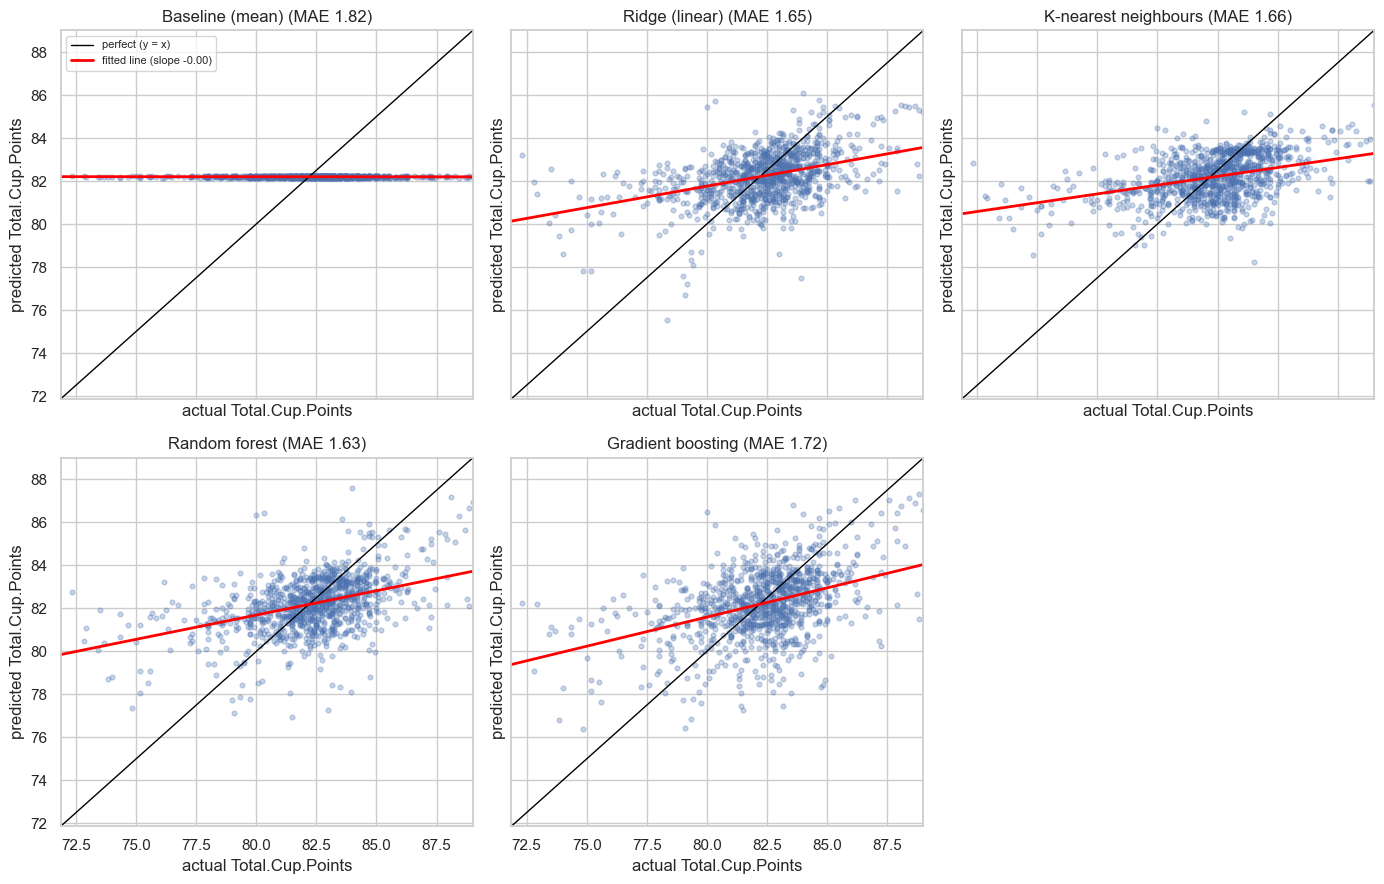

In [18]:
# Predicted against actual score for every model, with the perfect line (black) and the fitted regression line (red)
from sklearn.model_selection import cross_val_predict

fig, axes = plt.subplots(2, 3, figsize=(14, 9), sharex=True, sharey=True)
for ax, (name, model) in zip(axes.ravel(), models5.items()):
    pred = cross_val_predict(model, X_train, y_train, cv=cv)        # every lot is predicted by folds that never saw it
    plot_predicted_vs_actual(ax, y_train, pred, f"{name} (MAE {abs(y_train - pred).mean():.2f})")
axes.ravel()[0].legend(loc="upper left", fontsize=8)
axes.ravel()[-1].axis("off")                                         # 5 models, 6 panels
plt.tight_layout()
plt.show()

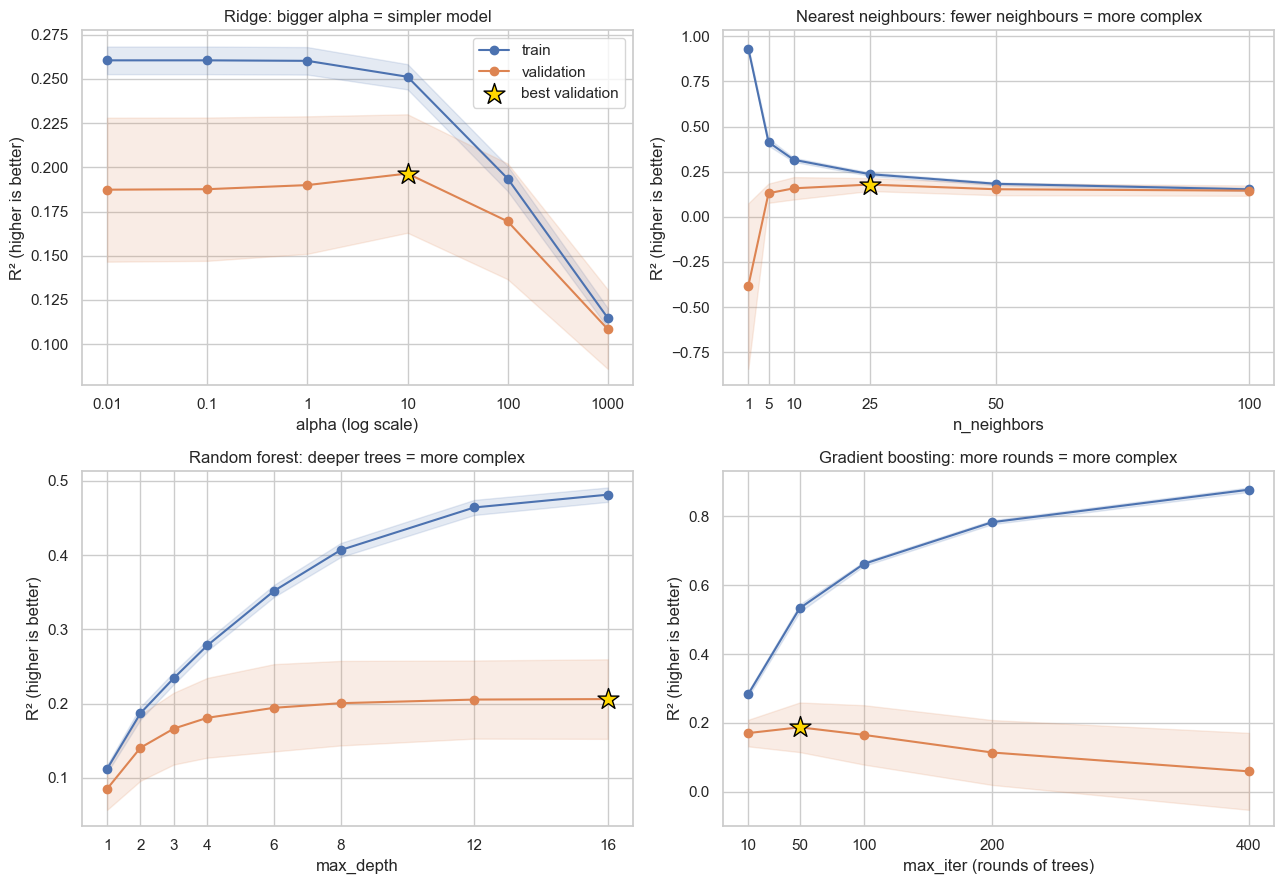

In [19]:
# The lesson plot: train against validation score while ONE setting of each model changes.
# Left of the best point = too simple (underfitting). Right of it = memorising (overfitting).
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
plot_validation_curve(axes[0, 0], models5["Ridge (linear)"], X_train, y_train, cv,
                      "model__alpha", [0.01, 0.1, 1, 10, 100, 1000],
                      "Ridge: bigger alpha = simpler model", "alpha (log scale)", log_x=True)
plot_validation_curve(axes[0, 1], models5["K-nearest neighbours"], X_train, y_train, cv,
                      "model__n_neighbors", [1, 5, 10, 25, 50, 100],
                      "Nearest neighbours: fewer neighbours = more complex", "n_neighbors")
plot_validation_curve(axes[1, 0], models5["Random forest"], X_train, y_train, cv,
                      "model__max_depth", [1, 2, 3, 4, 6, 8, 12, 16],
                      "Random forest: deeper trees = more complex", "max_depth")
plot_validation_curve(axes[1, 1], models5["Gradient boosting"], X_train, y_train, cv,
                      "model__max_iter", [10, 50, 100, 200, 400],
                      "Gradient boosting: more rounds = more complex", "max_iter (rounds of trees)")
axes[0, 0].legend()
plt.tight_layout()
plt.show()

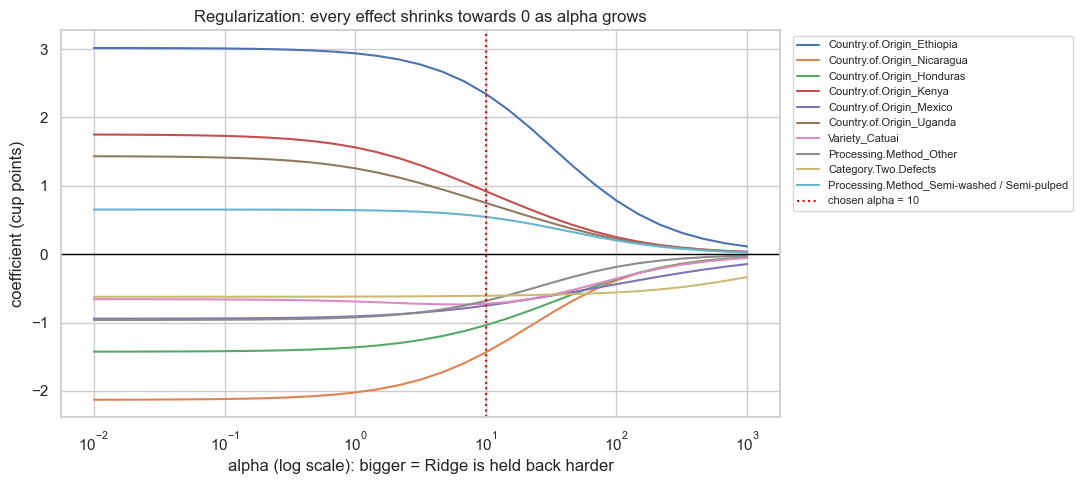

In [20]:
# Regularization from the inside: what happens to every coefficient as alpha grows?
from sklearn.linear_model import Ridge

alphas = np.logspace(-2, 3, 31)                            # includes alpha = 10, the value we chose
paths = []
for a in alphas:
    fitted = build_pipeline(Ridge(alpha=a), numeric_cols, categorical_cols).fit(X_train, y_train)
    paths.append(fitted.named_steps["model"].coef_)
names = fitted.named_steps["prep"].get_feature_names_out()
paths = pd.DataFrame(paths, index=alphas, columns=[c.replace("num__", "").replace("cat__", "") for c in names])

chosen = np.argmin(np.abs(alphas - 10))
loudest = paths.iloc[chosen].abs().sort_values(ascending=False).head(10).index     # the 10 biggest effects at alpha = 10

fig, ax = plt.subplots(figsize=(11, 5))
for col in loudest:
    ax.plot(alphas, paths[col], label=col)
ax.set_xscale("log")
ax.axhline(0, color="black", linewidth=1)
ax.axvline(10, color="red", linestyle=":", label="chosen alpha = 10")
ax.set_xlabel("alpha (log scale): bigger = Ridge is held back harder")
ax.set_ylabel("coefficient (cup points)")
ax.set_title("Regularization: every effect shrinks towards 0 as alpha grows")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1), fontsize=8)
plt.tight_layout()
plt.show()

There is real signal in two features. Altitude (r = 0.23): lots grown higher score higher. Category.Two.Defects (r = -0.28): more defects score lower. Category.One.Defects (-0.11) and Moisture (-0.14) are weaker. Total defects (r = -0.27) is no stronger than Category.Two alone (-0.28), which is why adding it changed nothing. Lots with a missing altitude score about the same as the rest. Lots with a missing moisture score a little higher (roughly half a point), but the missing flag still moved the forest by only 0.008, inside the noise. Decision: best_options = {}.
Caveat: r only sees straight-line links, and the defect lines are pulled by a few lots with many defects.

- Fold by fold, the lines run roughly parallel: fold 4 is hard for every model, fold 1 is easy, and the models keep their order, so the differences between them are steady.
- Predicted vs actual: every fitted line is much flatter than the perfect line, so all models play safe and predict close to the average. The baseline is perfectly flat.
- Ridge peaks at alpha ≈ 10, nearest neighbours at k ≈ 25, and the forest levels off from depth ≈ 8 (deeper trees only raise the train score). Gradient boosting peaks at about 50 rounds and falls from about 0.18 to 0.06 by 400 rounds. The default of 100 rounds sat past its peak, which is why default boosting was the worst model.
- All four families top out at a validation R² of about 0.18 to 0.22, so the ceiling seems to come from what the features contain, not from the algorithm.

---
## 6. Tune

A `GridSearchCV` or `RandomizedSearchCV` on the best one or two, on the training set. Report the best parameters and the cross-validated score.

In [21]:
from sklearn.model_selection import GridSearchCV

# Tune the two best from the table. Parameter names start with "model__" because the model is a step inside the pipeline.
rf = build_pipeline(RandomForestRegressor(n_estimators=200, random_state=RANDOM_STATE),
                    numeric_cols, categorical_cols, **best_options)
rf_grid = {"model__max_depth": [4, 8, 12, None],
           "model__min_samples_leaf": [1, 5, 10, 20],
           "model__max_features": [0.3, 0.6, 1.0]}

search = GridSearchCV(rf, rf_grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
search.fit(X_train, y_train)          # about a minute or two
print("Best parameters:", search.best_params_)
print("Cross-validated MAE:", round(-search.best_score_, 3), "| baseline:", round(baseline_mae, 3))

Best parameters: {'model__max_depth': 12, 'model__max_features': 0.3, 'model__min_samples_leaf': 5}
Cross-validated MAE: 1.597 | baseline: 1.819


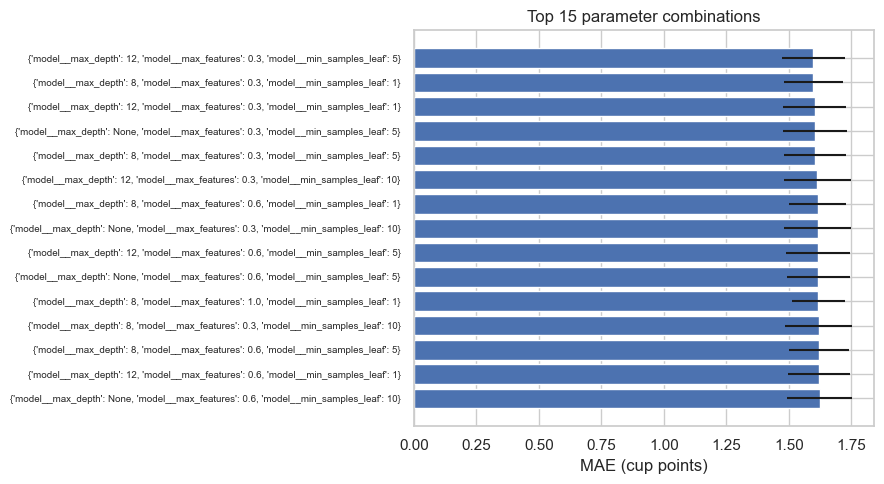

In [22]:
results = pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
top = results.head(15)

plt.figure(figsize=(9, 5))
plt.barh(range(len(top)), -top["mean_test_score"], xerr=top["std_test_score"])
plt.yticks(range(len(top)), [str(p) for p in top["params"]], fontsize=7)
plt.gca().invert_yaxis()
plt.xlabel("MAE (cup points)")
plt.title("Top 15 parameter combinations")
plt.tight_layout()
plt.show()

In [23]:
hgb = build_pipeline(HistGradientBoostingRegressor(random_state=RANDOM_STATE),
                     numeric_cols, categorical_cols, **best_options)
hgb_grid = {"model__learning_rate": [0.03, 0.1],
            "model__max_iter": [50, 100, 200, 400],          # NEW: learning rate and number of rounds work as a pair
            "model__max_depth": [3, None],
            "model__l2_regularization": [0.0, 1.0],
            "model__min_samples_leaf": [20, 40]}

search2 = GridSearchCV(hgb, hgb_grid, cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
search2.fit(X_train, y_train)
print("Best parameters:", search2.best_params_)
print("Cross-validated MAE:", round(-search2.best_score_, 3))

Best parameters: {'model__l2_regularization': 1.0, 'model__learning_rate': 0.03, 'model__max_depth': 3, 'model__max_iter': 100, 'model__min_samples_leaf': 20}
Cross-validated MAE: 1.633


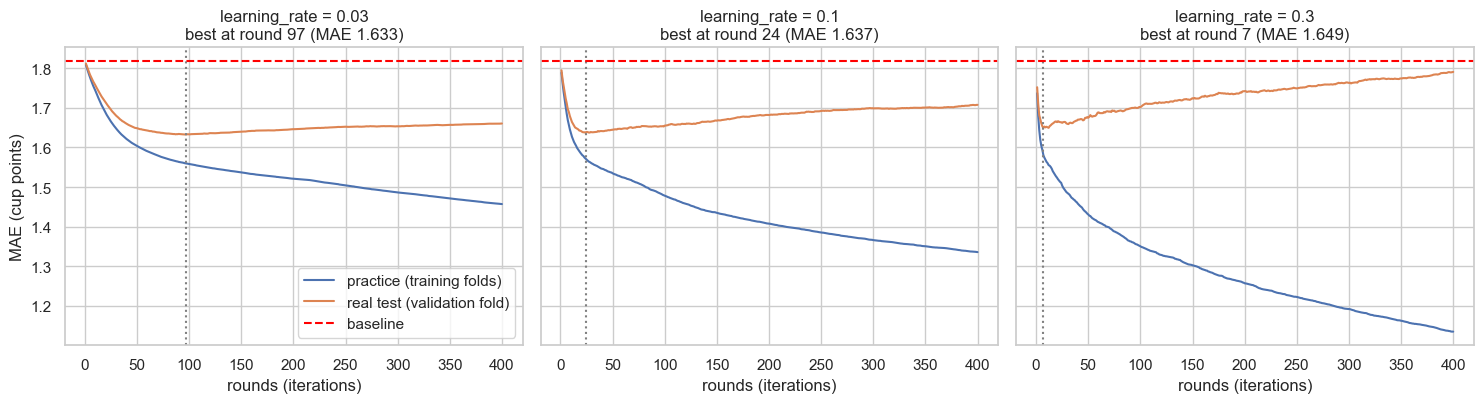

In [24]:
# Gradient descent in boosting: every round nudges the predictions a little, learning_rate sets the size of the nudge.
# Practice and validation MAE after each round, averaged over the 5 folds, for three nudge sizes.
from sklearn.base import clone
from sklearn.ensemble import HistGradientBoostingRegressor

rounds = 400
tuned = {name.replace("model__", ""): value for name, value in search2.best_params_.items()}
prep_template = search2.best_estimator_.named_steps["prep"]
n_folds = cv.get_n_splits()

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2), sharey=True)
for ax, rate in zip(axes, [0.03, 0.1, 0.3]):
    practice = np.zeros(rounds)
    validation = np.zeros(rounds)
    for train_idx, valid_idx in cv.split(X_train):
        prep = clone(prep_template).fit(X_train.iloc[train_idx])               # learned from the practice lots only
        Xt, Xv = prep.transform(X_train.iloc[train_idx]), prep.transform(X_train.iloc[valid_idx])
        yt, yv = y_train.iloc[train_idx].values, y_train.iloc[valid_idx].values
        booster = HistGradientBoostingRegressor(
            **{**tuned, "learning_rate": rate, "max_iter": rounds, "early_stopping": False},
            random_state=RANDOM_STATE).fit(Xt, yt)
        practice += np.abs(np.array(list(booster.staged_predict(Xt))) - yt).mean(axis=1) / n_folds
        validation += np.abs(np.array(list(booster.staged_predict(Xv))) - yv).mean(axis=1) / n_folds
    best_round = validation.argmin() + 1
    ax.plot(range(1, rounds + 1), practice, label="practice (training folds)")
    ax.plot(range(1, rounds + 1), validation, label="real test (validation fold)")
    ax.axvline(best_round, color="grey", linestyle=":")
    ax.axhline(baseline_mae, color="red", linestyle="--", label="baseline")
    ax.set_title(f"learning_rate = {rate}\nbest at round {best_round} (MAE {validation.min():.3f})")
    ax.set_xlabel("rounds (iterations)")
axes[0].set_ylabel("MAE (cup points)")
axes[0].legend()
plt.tight_layout()
plt.show()

Tuning helped gradient boosting a lot (1.72 to 1.63) because the settings I searched (a lower learning rate, a shallow tree depth and a penalty on the leaf values) calm the memorising. It helped the forest a little (1.63 to 1.60). In the forest grid, max_features = 0.3 fills the top rows: each split looks at a random 30 % of the columns, so the trees differ more from each other and the panel's average is better. Caveat: 1.597 is the best of 48 combinations, so it is slightly optimistic. The honest number comes from the test set in notebook 03.

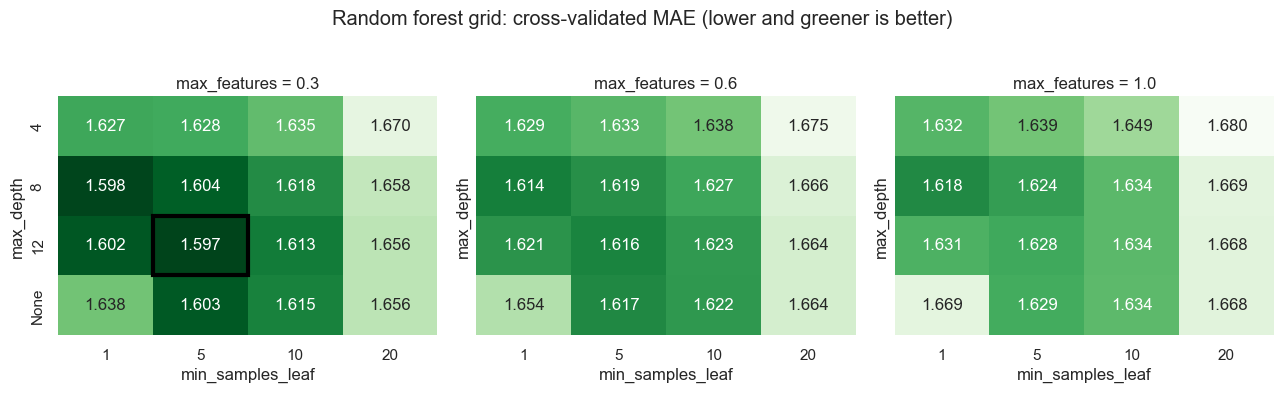

In [25]:
res = pd.DataFrame(search.cv_results_)
res["MAE"] = -res["mean_test_score"]
res["max_depth"] = res["param_model__max_depth"].astype(str)          # None becomes the text "None"
res["leaf"] = res["param_model__min_samples_leaf"].astype(int)
res["features"] = res["param_model__max_features"].astype(float)

depth_order = ["4", "8", "12", "None"]
leaf_order = sorted(res["leaf"].unique())
best = res.loc[res["MAE"].idxmin()]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
for ax, (share, part) in zip(axes, res.groupby("features")):
    grid = part.pivot(index="max_depth", columns="leaf", values="MAE").loc[depth_order, leaf_order]
    sns.heatmap(grid, annot=True, fmt=".3f", cmap="Greens_r", vmin=res["MAE"].min(), vmax=res["MAE"].max(),
                cbar=False, ax=ax)
    ax.set_title(f"max_features = {share}")
    ax.set_xlabel("min_samples_leaf")
    ax.set_ylabel("max_depth")
    if share == best["features"]:
        ax.add_patch(plt.Rectangle((leaf_order.index(best["leaf"]), depth_order.index(best["max_depth"])),
                                   1, 1, fill=False, edgecolor="black", linewidth=3))
plt.suptitle("Random forest grid: cross-validated MAE (lower and greener is better)", y=1.03)
plt.tight_layout()
plt.show()

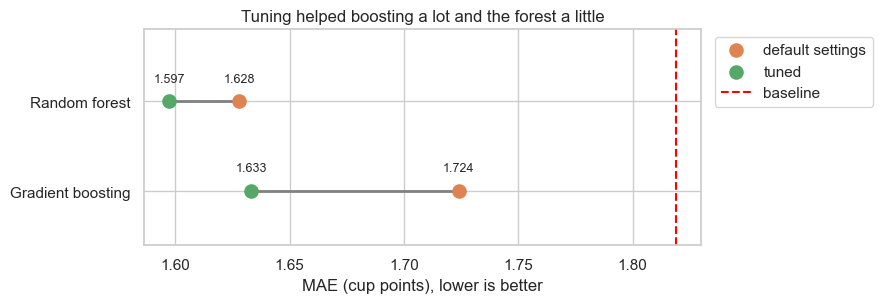

In [26]:
tuning = pd.DataFrame({
    "before": [comparison.loc["Random forest", "MAE (validation)"], comparison.loc["Gradient boosting", "MAE (validation)"]],
    "after": [-search.best_score_, -search2.best_score_]},
    index=["Random forest", "Gradient boosting"])

fig, ax = plt.subplots(figsize=(9, 3.2))
for i, (name, row) in enumerate(tuning.iterrows()):
    ax.plot([row["before"], row["after"]], [i, i], color="grey", linewidth=2, zorder=1)
    ax.scatter(row["before"], i, color="C1", s=90, zorder=2, label="default settings" if i == 0 else None)
    ax.scatter(row["after"], i, color="C2", s=90, zorder=2, label="tuned" if i == 0 else None)
    ax.text(row["before"], i - 0.22, f'{row["before"]:.3f}', ha="center", fontsize=9)
    ax.text(row["after"], i - 0.22, f'{row["after"]:.3f}', ha="center", fontsize=9)
ax.axvline(baseline_mae, color="red", linestyle="--", label="baseline")
ax.set_yticks(range(len(tuning)))
ax.set_yticklabels(tuning.index)
ax.set_ylim(len(tuning) - 0.4, -0.8)                                # room for the labels above the dots
ax.set_xlabel("MAE (cup points), lower is better")
ax.set_title("Tuning helped boosting a lot and the forest a little")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [27]:
# Cost function vs metric: Ridge and the boosting above learn by shrinking SQUARED error, but we report MAE.
# Squared error punishes the few duds (68, 69 points) very hard. These two versions learn from absolute error instead.
from sklearn.linear_model import HuberRegressor
from sklearn.ensemble import HistGradientBoostingRegressor

boost_params = {name.replace("model__", ""): value for name, value in search2.best_params_.items()}

loss_models = {
    "Ridge (squared error)": models5["Ridge (linear)"],
    "Huber, linear (robust to duds)": build_pipeline(HuberRegressor(alpha=10.0, epsilon=1.35, max_iter=1000),
                                                     numeric_cols, categorical_cols, **best_options),
    "Boosting, tuned (squared error)": search2.best_estimator_,
    "Boosting, tuned (absolute error)": build_pipeline(
        HistGradientBoostingRegressor(loss="absolute_error", random_state=RANDOM_STATE, **boost_params),
        numeric_cols, categorical_cols, **best_options),
}
loss_table = compare_models(loss_models, X_train, y_train, cv)
loss_table

,MAE (validation),MAE spread,R2 (validation),R2 spread,MAE (train)
"Huber, linear (robust to duds)",1.596,0.127,0.183,0.033,1.557
"Boosting, tuned (absolute error)",1.613,0.142,0.151,0.029,1.543
"Boosting, tuned (squared error)",1.633,0.115,0.190,0.048,1.558
Ridge (squared error),1.647,0.118,0.197,0.034,1.596


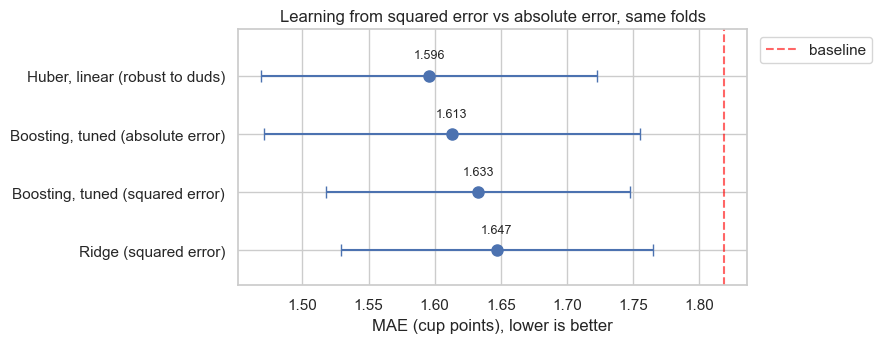

In [28]:
fig, ax = plt.subplots(figsize=(9, 3.6))
for i, (name, row) in enumerate(loss_table.iterrows()):
    ax.errorbar(row["MAE (validation)"], i, xerr=row["MAE spread"], fmt="o", capsize=4, color="C0", markersize=8)
    ax.text(row["MAE (validation)"], i - 0.3, f'{row["MAE (validation)"]:.3f}', ha="center", fontsize=9)
ax.axvline(baseline_mae, color="red", linestyle="--", alpha=0.6, label="baseline")
ax.set_yticks(range(len(loss_table)))
ax.set_yticklabels(loss_table.index)
ax.set_ylim(len(loss_table) - 0.4, -0.8)
ax.set_xlabel("MAE (cup points), lower is better")
ax.set_title("Learning from squared error vs absolute error, same folds")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout()
plt.show()

In [29]:
# Does Huber beat Ridge fold by fold? Same 5 folds, same idea as the forest-vs-Ridge check in section 6.
from sklearn.model_selection import cross_val_score

ridge_folds = -cross_val_score(loss_models["Ridge (squared error)"], X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")
huber_folds = -cross_val_score(loss_models["Huber, linear (robust to duds)"], X_train, y_train, cv=cv, scoring="neg_mean_absolute_error")

gain = ridge_folds - huber_folds                                   # positive = Huber wins that fold
print("MAE per fold, Ridge: ", ridge_folds.round(3))
print("MAE per fold, Huber: ", huber_folds.round(3))
print("Huber beats Ridge on", int((gain > 0).sum()), "of", len(gain), "folds")
print("Average gain:", round(gain.mean(), 3), "cup points, spread across folds:", round(gain.std(), 3))

MAE per fold, Ridge:  [1.518 1.559 1.589 1.828 1.74 ]
MAE per fold, Huber:  [1.461 1.492 1.548 1.802 1.679]
Huber beats Ridge on 5 of 5 folds
Average gain: 0.05 cup points, spread across folds: 0.015


**Cost function against metric.** Ridge and the boosting above learn by making the *squared* misses small, but I report the *average absolute* miss (MAE). Squared error pays a lot of attention to the few very bad lots (scores in the 60s and low 70s). Two versions that pay them less were tried on the same folds: a linear Huber model (squared error for small misses, a straight line for big ones) and boosting with absolute error. Both came out ahead of their squared-error twins: Huber 1.596 against Ridge 1.647, and boosting 1.613 against 1.633. The whiskers overlap, so the single numbers are not enough. Fold by fold, Huber beats Ridge on all 5 folds, by 0.05 cup points on average (spread about 0.02). That gain is as large as the tuned forest's over Ridge, and steadier, and Huber is just as easy to read. Two cautions: Huber's alpha was copied from Ridge and not tuned, and its R² is lower (0.183 against 0.197) because R² itself measures squared error, while the metric I chose is MAE.

**Decision:** Huber replaces Ridge as the final model. It beat Ridge on all 5 folds (0.05 cup points on average, spread about 0.02), it is a linear model just like Ridge so it is as simple and as readable, and it matched the tuned forest (1.596 against 1.597) without the 48-combination search behind that number. Honesty note: I had already scored Ridge once on the test set (MAE 1.605) when I tried this idea. The switch comes from cross-validation alone, but it means the test set is looked at twice, so the Huber test score is a little less clean than a single look would be. Both test scores are shown in notebook 03.

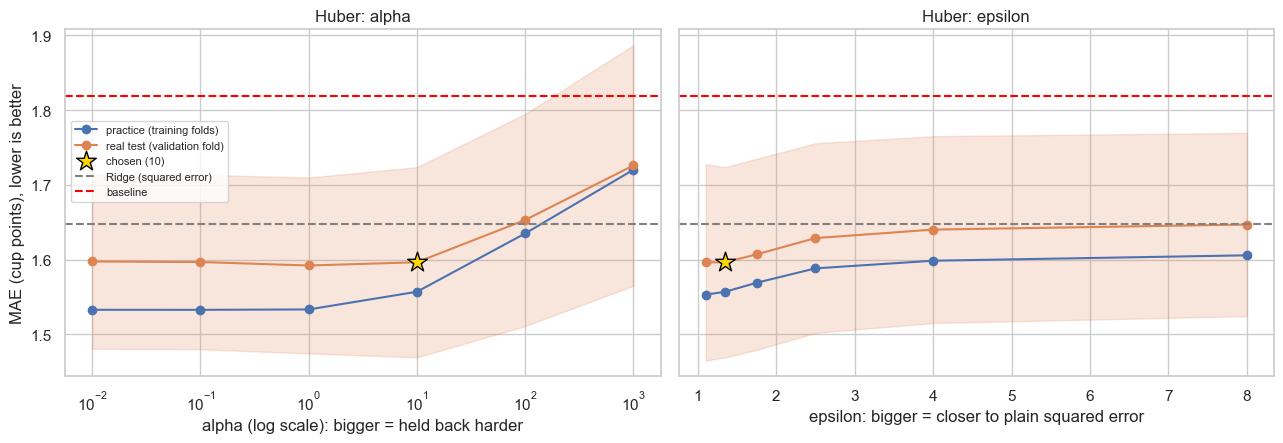

In [30]:
# Why alpha = 10 and epsilon = 1.35 for Huber? One setting at a time, the other stays as it is (MAE, lower is better).
from sklearn.linear_model import HuberRegressor
from sklearn.model_selection import validation_curve

huber = build_pipeline(HuberRegressor(alpha=10.0, epsilon=1.35, max_iter=1000), numeric_cols, categorical_cols, **best_options)
ridge_mae = comparison.loc["Ridge (linear)", "MAE (validation)"]

settings = [("model__alpha", [0.01, 0.1, 1, 10, 100, 1000], 10, "alpha (log scale): bigger = held back harder", True),
            ("model__epsilon", [1.1, 1.35, 1.75, 2.5, 4, 8], 1.35, "epsilon: bigger = closer to plain squared error", False)]

fig, axes = plt.subplots(1, 2, figsize=(13, 4.6), sharey=True)
for ax, (param, values, chosen, label, log_x) in zip(axes, settings):
    train_scores, valid_scores = validation_curve(huber, X_train, y_train, param_name=param, param_range=values,
                                                  cv=cv, scoring="neg_mean_absolute_error", n_jobs=-1)
    train_mae, valid_mae = -train_scores.mean(axis=1), -valid_scores.mean(axis=1)
    spread = valid_scores.std(axis=1)
    ax.plot(values, train_mae, marker="o", label="practice (training folds)")
    ax.plot(values, valid_mae, marker="o", label="real test (validation fold)")
    ax.fill_between(values, valid_mae - spread, valid_mae + spread, alpha=0.2, color="C1")
    ax.scatter(chosen, valid_mae[values.index(chosen)], marker="*", s=220, color="gold", edgecolor="black", zorder=5,
               label=f"chosen ({chosen})")
    ax.axhline(ridge_mae, color="grey", linestyle="--", label="Ridge (squared error)")
    ax.axhline(baseline_mae, color="red", linestyle="--", label="baseline")
    if log_x:
        ax.set_xscale("log")
    ax.set_xlabel(label)
axes[0].set_ylabel("MAE (cup points), lower is better")
axes[0].set_title("Huber: alpha")
axes[1].set_title("Huber: epsilon")
axes[0].legend(loc="center left", bbox_to_anchor=(0.0, 0.62), fontsize=8)
plt.tight_layout()
plt.show()

**Alpha and epsilon.** Alpha: from 0.01 to 10 the cross-validated MAE is flat (1.59 to 1.60; the lowest point is alpha = 1, only 0.004 better than the chosen 10), and above 10 Huber is held back too hard (about 1.65 at 100 and 1.73 at 1000). Epsilon: at 1.1 and 1.35 the MAE is 1.60. As epsilon grows, Huber behaves more and more like a plain squared-error model and slides up to about 1.65 at epsilon = 8, which is Ridge's score (the grey line). So the gain over Ridge comes from the robust loss, and it fades as the loss gets less robust. Alpha and epsilon were checked one at a time, not searched together, so 1.596 is not a best-of-many number.

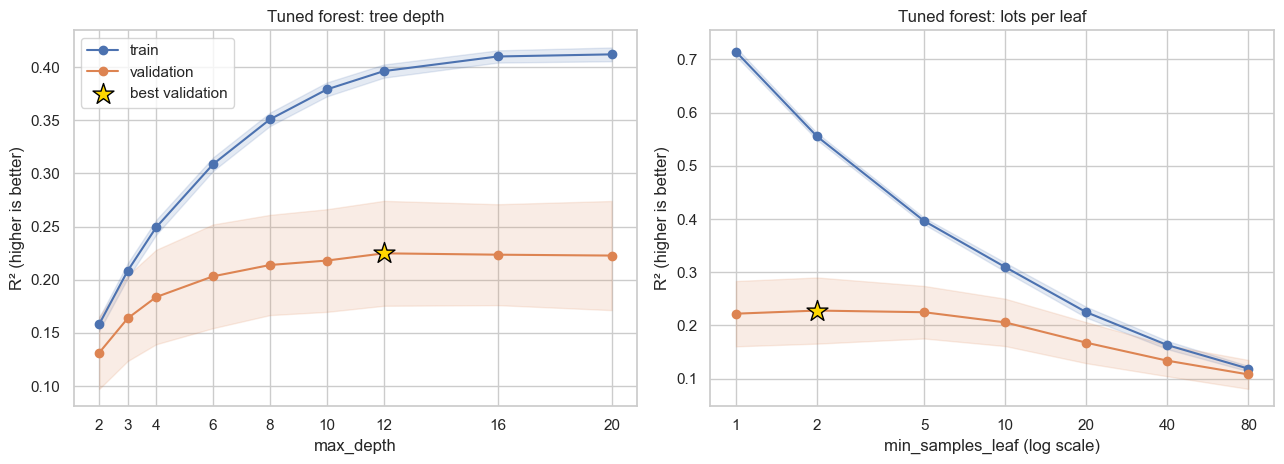

In [31]:
# Why the tuned settings? The same lesson plot for the tuned forest, one setting at a time (the others stay tuned).
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
plot_validation_curve(axes[0], search.best_estimator_, X_train, y_train, cv,
                      "model__max_depth", [2, 3, 4, 6, 8, 10, 12, 16, 20],
                      "Tuned forest: tree depth", "max_depth")
plot_validation_curve(axes[1], search.best_estimator_, X_train, y_train, cv,
                      "model__min_samples_leaf", [1, 2, 5, 10, 20, 40, 80],
                      "Tuned forest: lots per leaf", "min_samples_leaf (log scale)", log_x=True)
axes[0].legend()
plt.tight_layout()
plt.show()

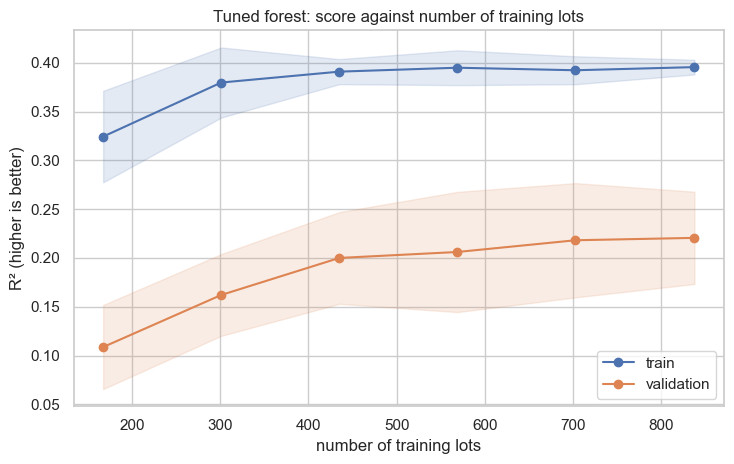

In [32]:
# Would more lots help? If the validation line is still climbing at the right edge, yes.
fig, ax = plt.subplots(figsize=(7.5, 4.8))
plot_learning_curve(ax, search.best_estimator_, X_train, y_train, cv,
                    "Tuned forest: score against number of training lots", RANDOM_STATE)
ax.legend()
plt.tight_layout()
plt.show()

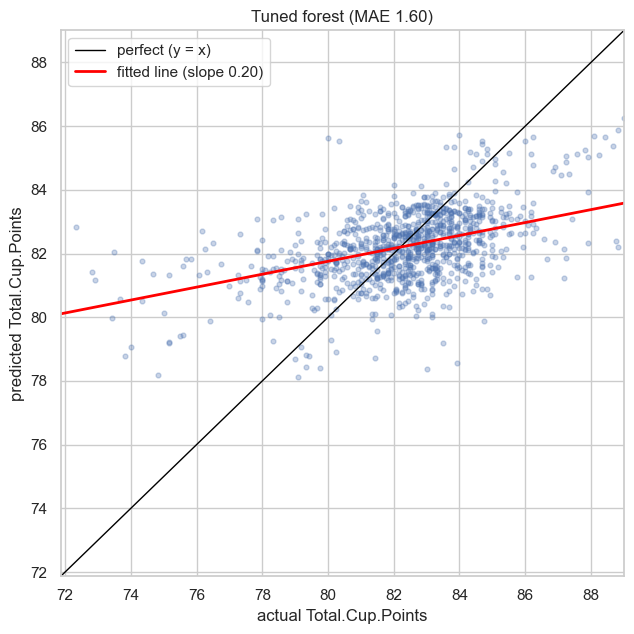

In [33]:
# Predicted against actual for the tuned forest, with the regression line
pred = cross_val_predict(search.best_estimator_, X_train, y_train, cv=cv)

fig, ax = plt.subplots(figsize=(6.5, 6.5))
plot_predicted_vs_actual(ax, y_train, pred, f"Tuned forest (MAE {abs(y_train - pred).mean():.2f})")
ax.legend(loc="upper left")
plt.tight_layout()
plt.show()

The validation curves show the tuned forest sits on a plateau, not a lucky spike: depth levels off around 12 and 1 to 5 lots per leaf score the same. The learning curve is still creeping up at 840 lots (validation R² from about 0.11 at 170 lots to 0.22) with a gap of about 0.18 to the training line, so more lots would help, slowly. That is a point for the presentation: 1,310 Arabica lots is below what this problem would like.
Finalists: the tuned forest beats Ridge on 4 of 5 folds, with an average gain of 0.049 cup points (spread 0.044 across folds).

---
## 7. Threshold

Classification only. Cross-validated probabilities on the training set with `cross_val_predict`, then the threshold that fits your metric and the cost of each mistake. Regression: delete this section and say why in the README.

This is a regression, so there is no class threshold, and this section is removed (the README says why). The nearest real decision is the 80-point specialty line, so I check below how often we put a lot on the right side of it.

Right side of the 80 line: 0.874
Always saying 'specialty' (no model at all): 0.865
Sub-80 lots caught: 8% | flagged lots that really are sub-80: 85%


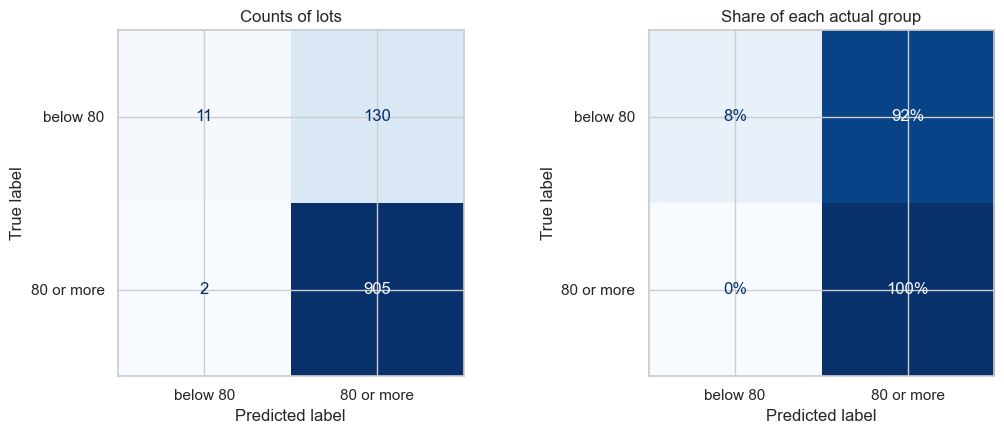

In [34]:
# The decision we CAN ask of a regression: is this lot below the 80-point specialty line?
# The final model is Huber, so this uses Huber. cross_val_predict refits it on every fold.
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import ConfusionMatrixDisplay, accuracy_score, precision_score, recall_score

final = loss_models["Huber, linear (robust to duds)"]               # the final model (alpha = 10, epsilon = 1.35), the same one as in section 8
pred = cross_val_predict(final, X_train, y_train, cv=cv)            # each lot is predicted by a model that never saw it
actual_specialty = y_train >= 80
says_specialty = pred >= 80

print("Right side of the 80 line:", round(accuracy_score(actual_specialty, says_specialty), 3))
print("Always saying 'specialty' (no model at all):", round(actual_specialty.mean(), 3))
print("Sub-80 lots caught:", f"{recall_score(~actual_specialty, ~says_specialty):.0%}",
      "| flagged lots that really are sub-80:", f"{precision_score(~actual_specialty, ~says_specialty, zero_division=0):.0%}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
labels = ["below 80", "80 or more"]
ConfusionMatrixDisplay.from_predictions(actual_specialty, says_specialty, display_labels=labels,
                                        cmap="Blues", colorbar=False, ax=axes[0])
axes[0].set_title("Counts of lots")
ConfusionMatrixDisplay.from_predictions(actual_specialty, says_specialty, display_labels=labels,
                                        normalize="true", values_format=".0%", cmap="Blues", colorbar=False, ax=axes[1])
axes[1].set_title("Share of each actual group")
plt.tight_layout()
plt.show()

**The 80-point line, for Huber.** This section uses the final model, Huber, with cross-validated predictions on the training lots, so the test set stays untouched. The printed lines above give the numbers at the 80 line: how often Huber puts a lot on the right side of it, how that compares with always saying "specialty", and how many of the sub-80 lots it catches. Because Huber pulls its predictions toward the average, a cut-off at 80 flags very few lots. Raising the cut-off catches more of the sub-80 lots but flags more good lots too, so the right cut-off depends on cost: a second cupping costs time, a missed sub-80 lot costs a bad sale.

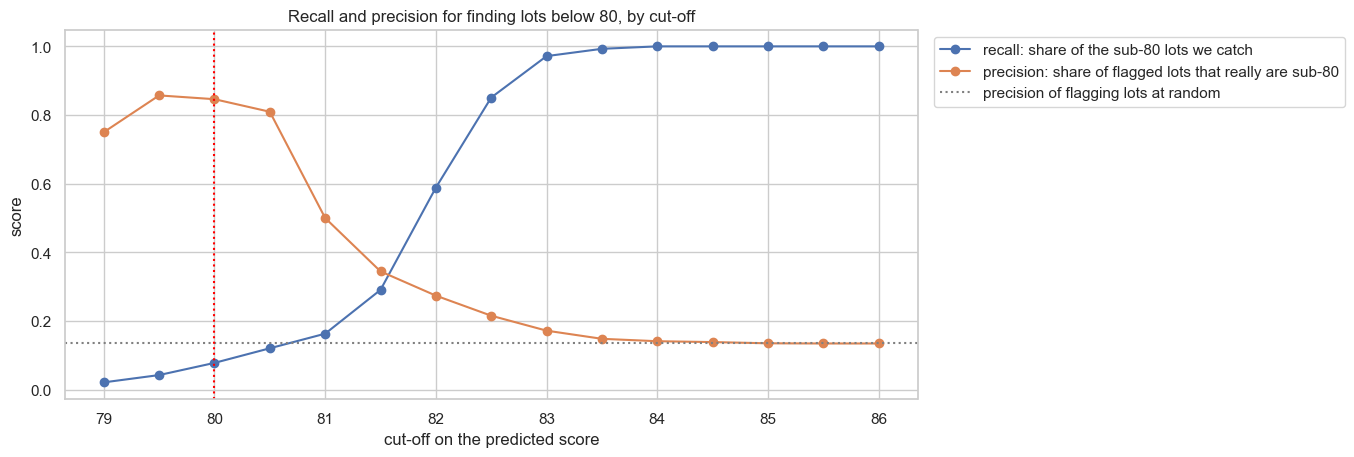

In [35]:
# Choosing the cut-off: flag a lot for a second cupping when its predicted score is below the cut-off
from sklearn.metrics import precision_score, recall_score

below_80 = y_train < 80
cutoffs = np.arange(79, 86.5, 0.5)
recall = [recall_score(below_80, pred < c, zero_division=0) for c in cutoffs]
precision = [precision_score(below_80, pred < c, zero_division=0) for c in cutoffs]

plt.figure(figsize=(11, 4.8))
plt.plot(cutoffs, recall, marker="o", label="recall: share of the sub-80 lots we catch")
plt.plot(cutoffs, precision, marker="o", label="precision: share of flagged lots that really are sub-80")
plt.axhline(below_80.mean(), color="grey", linestyle=":", label="precision of flagging lots at random")
plt.axvline(80, color="red", linestyle=":")
plt.xlabel("cut-off on the predicted score")
plt.ylabel("score")
plt.title("Recall and precision for finding lots below 80, by cut-off")
plt.legend(loc="upper left", bbox_to_anchor=(1.01, 1))
plt.show()

In [36]:
cutoff_table = pd.DataFrame({"cut-off": cutoffs, "recall": recall, "precision": precision,
                             "share of lots flagged": [(pred < c).mean() for c in cutoffs]}).round(2)
cutoff_table[cutoff_table["cut-off"].isin([80, 81, 82, 83])]

,cut-off,recall,precision,share of lots flagged
2,80.0,0.08,0.85,0.01
4,81.0,0.16,0.50,0.04
6,82.0,0.59,0.27,0.29
8,83.0,0.97,0.17,0.76


**The 80-point line, for Huber.** This section uses the final model, Huber, with cross-validated predictions on the training lots, so the test set stays untouched. At the 80 line Huber is on the right side 87.4 % of the time, against 86.5 % for always saying "specialty": almost no gain. It flags only 1 % of the lots, catches 8 % of the sub-80 lots, and 85 % of the lots it flags really are sub-80. Raising the cut-off catches more weak lots but flags more good ones: at 82 it catches 59 % of the sub-80 lots while flagging 29 % of all lots (27 % of those really are weak), and at 83 it catches 97 % but flags 76 % of all lots. The right cut-off depends on cost: a second cupping costs time, a missed sub-80 lot costs a bad sale.

---
## 8. The final model

Which model, which parameters, which threshold, and why. If a simpler model is within the noise of the best one, say which you chose and why.

In [37]:
import joblib

final_model = loss_models["Huber, linear (robust to duds)"]   # Huber, alpha = 10, epsilon = 1.35, no extra features
final_model.fit(X_train, y_train)                             # fitted once on the whole training set; the test set stays untouched

os.makedirs(PATHS["model_dir"], exist_ok=True)
joblib.dump(final_model, os.path.join(PATHS["model_dir"], "final_model.joblib"))     # models/ is gitignored

reloaded = joblib.load(os.path.join(PATHS["model_dir"], "final_model.joblib"))
print("Reloaded:", type(reloaded.named_steps["model"]).__name__,
      "| same predictions:", bool((reloaded.predict(X_train[:5]) == final_model.predict(X_train[:5])).all()))

Reloaded: HuberRegressor | same predictions: True


**Final model:** Huber regression (alpha = 10, epsilon = 1.35), inside the preprocessing pipeline, no extra features. It is a linear model like Ridge, but it learns from squared error for small misses and absolute error for big ones, so the few very bad lots pull it around less.
**CV MAE:** 1.596 cup points (baseline 1.819), R² about 0.18.
**Why this one:** it beat Ridge on all 5 folds (0.05 cup points on average, spread about 0.02), it matched the tuned forest (1.597, the best of 48 combinations) with settings that were checked one at a time, not searched, and it is as simple and as readable as Ridge.
Saved to models/final_model.joblib (not committed). The test set is scored in notebook 03. Ridge was scored there first (see the note in 03), so the test set has been looked at twice.

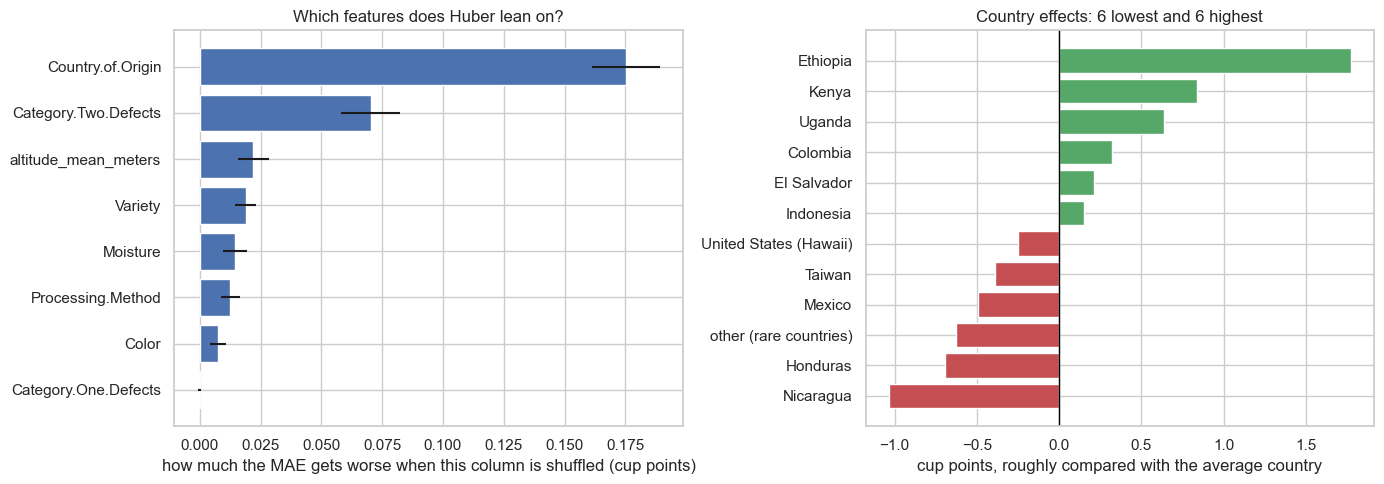

In [38]:
# Which features does Huber lean on, and which countries push the score up or down?
from sklearn.inspection import permutation_importance

result = permutation_importance(final_model, X_train, y_train, scoring="neg_mean_absolute_error",
                                n_repeats=20, random_state=RANDOM_STATE, n_jobs=-1)
importance = pd.DataFrame({"feature": X_train.columns, "MAE gets worse by": result.importances_mean,
                           "spread": result.importances_std}).sort_values("MAE gets worse by")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].barh(importance["feature"], importance["MAE gets worse by"], xerr=importance["spread"])
axes[0].set_xlabel("how much the MAE gets worse when this column is shuffled (cup points)")
axes[0].set_title("Which features does Huber lean on?")

coefs = pd.Series(final_model.named_steps["model"].coef_, index=final_model.named_steps["prep"].get_feature_names_out())
countries = coefs[coefs.index.str.startswith("cat__Country.of.Origin_")]
countries.index = (countries.index.str.replace("cat__Country.of.Origin_", "", regex=False)
                                  .str.replace("infrequent_sklearn", "other (rare countries)", regex=False))
extremes = pd.concat([countries.nsmallest(6), countries.nlargest(6)]).sort_values()
axes[1].barh(extremes.index, extremes.values, color=["C2" if v > 0 else "C3" for v in extremes.values])
axes[1].axvline(0, color="black", linewidth=1)
axes[1].set_xlabel("cup points, roughly compared with the average country")
axes[1].set_title("Country effects: 6 lowest and 6 highest")
plt.tight_layout()
plt.show()

---
## Image option

If you chose the flower photos, sections 2 to 7 become: rescaling and augmentation layers; a CNN from scratch trained with early stopping, with its training curves; a frozen pretrained network (for example `MobileNetV2`) with a new output layer, trained the same way; and the two compared on the validation set. Fine-tuning the top of the pretrained network is optional.